<a href="https://colab.research.google.com/github/xudavid715-cloud/Problem-Set-5-Right-93-of-the-Time-Rubric/blob/main/Econ_3916_PS5_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Right 93% of the Time
**David Xu · ECON 3916 · Problem Set 5**

Should the lender decline a loan? I compare the vendor’s accuracy claim with approving every applicant, then price the mistakes each policy makes. All loans and dollar outcomes below are simulated.

## 1 · Applications and the approval baseline
The generator gives each application an independent default draw. Income, debt burden, years of credit history, prior delinquencies and principal enter the log odds directly. The audit fields are independently generated noise. I reserve a final test set immediately, then divide development data into model-fit, calibration and policy-validation sets. The split seed, cost rules and model-selection criterion are fixed in code.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logit
from scipy.stats import binomtest, chi2
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
    auc, brier_score_loss)
seed = 3916
rng = np.random.default_rng(seed)
n = 24000
income = np.round(np.clip(rng.lognormal(np.log(65000), .48, n), 18000, 300000))
dti = rng.beta(2.8, 5.6, n)
history = rng.uniform(1, 35, n)
late = rng.poisson(.6, n)
loan = np.round(rng.uniform(3000, 42000, n), -2)
noise = ['audit_draw', 'batch_bucket', 'routing_flag']
X = pd.DataFrame(dict(income=income, debt_to_income=dti, history_years=history,
    prior_delinquencies=late, loan_amount=loan, audit_draw=rng.random(n),
    batch_bucket=rng.integers(0, 12, n), routing_flag=rng.integers(0, 2, n)))
eta = (-3.43 - .000011*(income-65000) + 6.6*(dti-1/3)
       - .055*(history-18) + 1.03*(late-.6) + .000028*(loan-22500))
y = rng.binomial(1, expit(eta))
Xd, X_test, yd, y_test = train_test_split(X, y, test_size=.25, random_state=seed, stratify=y)
X_fit, Xhold, y_fit, yhold = train_test_split(Xd, yd, test_size=1/3, random_state=seed+1, stratify=yd)
X_cal, X_val, y_cal, y_val = train_test_split(Xhold, yhold, test_size=.5, random_state=seed+2, stratify=yhold)
null = DummyClassifier(strategy='constant', constant=0).fit(X_fit, y_fit)
null_acc = accuracy_score(y_test, null.predict(X_test))
print(f'Test applications {len(y_test):,} | defaults {sum(y_test):,} | prevalence {y_test.mean():.2%} | approve-all accuracy {null_acc:.2%}')

Test applications 6,000 | defaults 413 | prevalence 6.88% | approve-all accuracy 93.12%


Approving everyone is right on 93.12% of test applications and flags none of the 413 defaults. That is the floor every model below has to clear.

The sentence for the meeting: **a model that has learned nothing scores 93%, so the vendor’s 93% is not evidence that its model has learned anything.** Section 2 tests whether our own models clear that floor convincingly, and Section 3 shows why accuracy is the wrong yardstick anyway.

## 2 · Fit and regularise
All three logistic models see the same features. Standardisation is fitted inside each fold. Five-fold stratified cross-validation minimises log loss because the subsequent decision uses probabilities. I choose the better penalised family using only these training folds.

plain test accuracy 0.93517
lasso test accuracy 0.935
ridge test accuracy 0.935
CV-selected C: {'lasso': 0.1, 'ridge': 0.31622776601683794} | chosen: lasso
                       plain    lasso    ridge
income              -0.34880 -0.32364 -0.34563
debt_to_income       0.98816  0.96495  0.98187
history_years       -0.53741 -0.51627 -0.53341
prior_delinquencies  0.74322  0.72586  0.73915
loan_amount          0.33807  0.31828  0.33557
audit_draw           0.01553  0.00036  0.01548
batch_bucket         0.00727  0.00000  0.00722
routing_flag        -0.02596 -0.01032 -0.02580
Exact LASSO zeros: ['batch_bucket']

1-SE rule: C = 0.0316 | exact zeros: ['audit_draw', 'batch_bucket', 'routing_flag']
Noise fields zeroed 3/3 | real predictors dropped 0/5
Test accuracy 0.9345 vs 0.9350 | test AP 0.3764 vs 0.3759


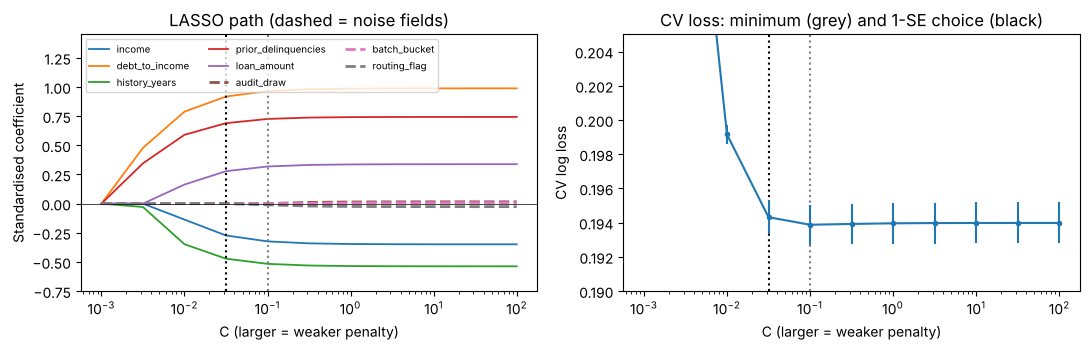

In [ ]:
import sklearn
# C is inverse penalty strength. 'C=np.inf' is supported in newer sklearn.
from packaging.version import Version
modern = Version(sklearn.__version__) >= Version('1.8')
def logistic(kind):
    if modern:
        opts = {'C': np.inf} if kind == 'plain' else {'l1_ratio': float(kind == 'lasso')}
    else:
        opts = {'penalty': {'plain': None, 'lasso': 'l1', 'ridge': 'l2'}[kind]}
    return make_pipeline(StandardScaler(), LogisticRegression(solver='saga', max_iter=2500,
                         tol=1e-6, random_state=seed, **opts))
plain = logistic('plain').fit(X_fit, y_fit)
cv = StratifiedKFold(5, shuffle=True, random_state=seed)
fits = {}
for kind in ['lasso', 'ridge']:
    fit = GridSearchCV(logistic(kind), {'logisticregression__C': np.logspace(-3, 2, 11)},
                       scoring='neg_log_loss', cv=cv)
    fits[kind] = fit.fit(X_fit, y_fit)
winner = max(fits, key=lambda k: fits[k].best_score_)
model = fits[winner].best_estimator_
coefs = pd.DataFrame(index=X.columns)
for k, pipe in [('plain', plain)] + [(k, f.best_estimator_) for k, f in fits.items()]:
    coefs[k] = pipe[-1].coef_[0]
    print(k, 'test accuracy', round(pipe.score(X_test, y_test), 5))
print('CV-selected C:', {k: float(f.best_params_['logisticregression__C']) for k,f in fits.items()}, '| chosen:', winner)
print(coefs.round(5))
zero = set(coefs.index[coefs.lasso == 0])
print('Exact LASSO zeros:', sorted(zero))

# The whole LASSO path, and the one-standard-error rule as a sparser alternative.
res = fits['lasso'].cv_results_
Cs = np.asarray(res['param_logisticregression__C'], dtype=float)
cv_loss = -res['mean_test_score']
cv_se = res['std_test_score'] / np.sqrt(cv.get_n_splits())
c_min = float(fits['lasso'].best_params_['logisticregression__C'])
c_1se = Cs[cv_loss <= cv_loss.min() + cv_se[cv_loss.argmin()]].min()   # strongest penalty within 1 SE
path = pd.DataFrame([logistic('lasso').set_params(logisticregression__C=C).fit(X_fit, y_fit)[-1].coef_[0]
                     for C in Cs], index=Cs, columns=X.columns)
lasso_1se = logistic('lasso').set_params(logisticregression__C=c_1se).fit(X_fit, y_fit)
zero_1se = sorted(X.columns[lasso_1se[-1].coef_[0] == 0])
print(f'\n1-SE rule: C = {c_1se:.4f} | exact zeros: {zero_1se}')
print(f'Noise fields zeroed {len(set(zero_1se) & set(noise))}/3 | real predictors dropped {len(set(zero_1se) - set(noise))}/5')
print(f'Test accuracy {lasso_1se.score(X_test, y_test):.4f} vs {model.score(X_test, y_test):.4f} | '
      f'test AP {average_precision_score(y_test, lasso_1se.predict_proba(X_test)[:,1]):.4f} vs '
      f'{average_precision_score(y_test, model.predict_proba(X_test)[:,1]):.4f}')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for col in X.columns:
    ax[0].plot(Cs, path[col], ls='--' if col in noise else '-', lw=2 if col in noise else 1.3, label=col)
for a in ax:
    a.axvline(c_min, color='gray', ls=':'); a.axvline(c_1se, color='black', ls=':')
    a.set_xscale('log'); a.set_xlabel('C (larger = weaker penalty)')
ax[0].axhline(0, color='black', lw=.5)
ax[0].set(ylabel='Standardised coefficient', title='LASSO path (dashed = noise fields)', ylim=(-.75, 1.45))
ax[0].legend(fontsize=7, ncol=3, loc='upper left')
ax[1].errorbar(Cs, cv_loss, yerr=cv_se, marker='o', ms=3)
ax[1].set(ylabel='CV log loss', title='CV loss: minimum (grey) and 1-SE choice (black)', ylim=(.19, .205))
fig.tight_layout()
plt.show()

**What LASSO removed.** At the cross-validated minimum (C = 0.1), LASSO set only batch_bucket exactly to zero: it found 1 of the 3 noise fields and discarded 0 of the 5 genuine predictors. audit_draw (0.0004) and routing_flag (−0.0103) survived with coefficients close to zero. That is what minimum-loss selection tends to do. The right-hand plot shows the CV loss is almost flat from C = 0.1 upward, so cross-validation has no reason to prefer the stronger penalty that would remove them.

The one-standard-error rule picks the strongest penalty whose CV loss is within one standard error of the best. It selects C = 0.0316, sets **all three** noise fields to zero, keeps all five real predictors, and gives up almost nothing on the test set: accuracy 93.45% against 93.50%, average precision 0.376 against 0.376. On the path plot, the five real predictors enter first as the penalty weakens and the noise fields enter last, at tiny magnitudes. I keep the CV-minimum model for the rest of the analysis. The 1-SE model performs the same on test, so the choice changes no conclusion below.

**Why LASSO zeros and Ridge only shrinks.** Each penalty charges a cost for moving a coefficient away from zero. LASSO’s penalty λ|β| charges the same marginal cost λ for every unit, however close β is to zero. If the improvement in fit from the first small step away from zero is worth less than λ, the step is not taken and the coefficient stays at exactly zero. Ridge’s penalty λβ² has slope 2λβ, which is zero at β = 0. The first step away from zero is free, so any signal at all, however weak, moves the coefficient off zero. Ridge pulls every coefficient toward zero but leaves it nonzero.

**When to prefer each.** I would use LASSO when the lender wants a short scorecard or believes many candidate fields are irrelevant: a dropped variable no longer has to be collected, monitored or explained to a regulator. I would use Ridge when several correlated predictors each carry some signal, such as three different measures of indebtedness. LASSO tends to keep one of them more or less arbitrarily and drop the rest, so its selection can flip from sample to sample, while Ridge spreads the weight across all of them and is more stable.

In [ ]:
rf = RandomForestClassifier(n_estimators=500, bootstrap=True, oob_score=True,
    min_samples_leaf=8, random_state=seed, n_jobs=-1).fit(X_fit, y_fit)
forest_pred = rf.predict(X_test)
logistic_pred = model.predict(X_test)
rf_acc = accuracy_score(y_test, forest_pred)
lr_acc = accuracy_score(y_test, logistic_pred)
y_prob = model.predict_proba(X_test)[:,1]
rf_prob = rf.predict_proba(X_test)[:,1]
print(f'OOB accuracy {rf.oob_score_:.4f}, OOB error {1-rf.oob_score_:.4f}, test accuracy {rf_acc:.4f}, test error {1-rf_acc:.4f}')
print('Test average precision | forest, logistic:', average_precision_score(y_test,rf_prob), average_precision_score(y_test,y_prob))

# Does either model beat approve-all convincingly? Paired comparison on the same test rows.
approve_all = np.zeros_like(y_test)
for name, pred in [('LASSO', logistic_pred), ('forest', forest_pred)]:
    gain = int(sum((pred == y_test) & (approve_all != y_test))), int(sum((pred != y_test) & (approve_all == y_test)))
    b0, c0 = gain
    p0 = chi2.sf(max(0, abs(b0 - c0) - 1)**2 / (b0 + c0), 1)
    print(f'{name} vs approve-all: accuracy {accuracy_score(y_test, pred):.4f} vs {null_acc:.4f} '
          f'(+{b0 - c0} correct rows of {len(y_test):,}); b={b0}, c={c0}, McNemar p={p0:.4g}')

imp = permutation_importance(rf, X_test, y_test, scoring='average_precision',
                             n_repeats=5, random_state=seed)
importance = pd.DataFrame({'MDI':rf.feature_importances_, 'AP drop':imp.importances_mean,
                           'shuffle SD':imp.importances_std}, index=X.columns)
importance['MDI rank'] = importance.MDI.rank(ascending=False).astype(int)
importance['perm rank'] = importance['AP drop'].rank(ascending=False).astype(int)
print(importance.sort_values('MDI', ascending=False).round(4))

# Importance is not a lever: loan_amount is the one input the lender controls.
crossover = .09 / (.60 + .09)          # cost-based cutoff derived in Phase 3
declined = y_prob >= crossover
half = X_test.assign(loan_amount=X_test.loan_amount / 2)
p_half = model.predict_proba(half)[:,1]
print(f'Declined at the {crossover:.1%} cost cutoff: {declined.sum()} | predicted PD {y_prob[declined].mean():.3f} '
      f'-> {p_half[declined].mean():.3f} at half the loan | would clear the cutoff: {(p_half[declined] < crossover).sum()}')

OOB accuracy 0.9322, OOB error 0.0678, test accuracy 0.9342, test error 0.0658
Test average precision | forest, logistic: 0.35873727436471803 0.3758917920334402
LASSO vs approve-all: accuracy 0.9350 vs 0.9312 (+23 correct rows of 6,000); b=49, c=26, McNemar p=0.01107
forest vs approve-all: accuracy 0.9342 vs 0.9312 (+18 correct rows of 6,000); b=19, c=1, McNemar p=0.0001439
                        MDI  AP drop  shuffle SD  MDI rank  perm rank
debt_to_income       0.2921   0.1890      0.0097         1          2
prior_delinquencies  0.1545   0.1911      0.0052         2          1
history_years        0.1472   0.0682      0.0125         3          3
income               0.1200   0.0228      0.0066         4          5
loan_amount          0.1138   0.0331      0.0051         5          4
audit_draw           0.1045   0.0046      0.0043         6          6
batch_bucket         0.0527  -0.0013      0.0020         7          8
routing_flag         0.0152   0.0018      0.0007         8     

**OOB versus test.** OOB accuracy is 93.22% and test accuracy is 93.42%. They should be close because each OOB vote comes only from trees that never saw that row, so OOB is already an out-of-sample estimate drawn from the same population as the test set. A large gap would point to leakage, a shift between the training and test populations, or sampling noise in a small test set.

**Forest versus penalised logistic.** The forest does not win. At 0.5 it scored 93.42% against LASSO’s 93.50%. On average precision, the better summary at 7% prevalence, it scored 0.359 against 0.376. The expensive model is behind on both measures, and the cheap one is the model the lender can explain to a regulator coefficient by coefficient.

**Against the floor.** Both models beat approve-all, but by very little on accuracy: LASSO by 0.38 points (23 more correct rows out of 6,000) and the forest by 0.30 points (18 rows). A paired McNemar test against approve-all says both gains are real (p = 0.011 and p = 0.0001), so the models have learned something. But a gain of a few dozen rows is exactly why accuracy cannot separate a good model from a useless one here, and why Section 3 prices the errors instead.

**MDI versus permutation importance.** The clearest disagreement is audit_draw, a pure-noise continuous field. It receives 0.104 of total split importance, nearly as much as income and loan amount, yet shuffling it lowers test average precision by only 0.0046, which is within one shuffle standard deviation of zero. The two methods also disagree on the real predictors. MDI rates history_years (0.147) almost equal to prior_delinquencies (0.155), while permutation says delinquencies matter almost three times as much (0.191 against 0.068). MDI also ranks income above loan amount; permutation reverses them.

MDI inflates high-cardinality features because it adds up impurity reductions measured on the training data. A continuous or many-valued feature offers hundreds of candidate split points, so by chance some split on it will reduce impurity in-sample, and every such lucky split is credited to it even when it does not generalise. prior_delinquencies is a small count with few possible cuts, so it gets fewer chances to be lucky. Permutation importance measures how much test performance falls when a feature is scrambled, so in-sample luck earns nothing.

**Importance is not effect.** A feature is important when it helps predict default, not when changing it would change default. The feature where this matters most is **loan_amount**, because it is the one input the lender controls. The model invites a counteroffer policy: at the 13% cost-based cutoff from Phase 3, it would decline 843 test applicants, and 265 of them would fall below the cutoff if offered half the loan, with average predicted risk falling from 27.3% to 21.3%.

In this simulation that reasoning is legitimate, because I built loan size into default risk causally. In real lending data it would not be. Lenders already set loan amounts partly by perceived risk, and applicants who ask for large loans differ in ways the model cannot see, so the loan-amount coefficient mixes the effect of the loan’s size with who asks for big loans. Before using the model to size counteroffers, the lender would need evidence that cutting the loan actually lowers default, ideally a randomised test of counteroffer amounts. Income is the opposite case: it helps predict, but no lending decision changes it, so its importance tells the lender nothing about what to do differently.

## 3 · Which mistakes does accuracy hide?

Rows actual good/default; columns approve/decline
[[5561   26]
 [ 364   49]]
precision             0.6533
recall                0.1186
F1                    0.2008
ROC_AUC               0.8318
AP                    0.3759
trapezoidal_PR_AUC    0.3751
dtype: float64


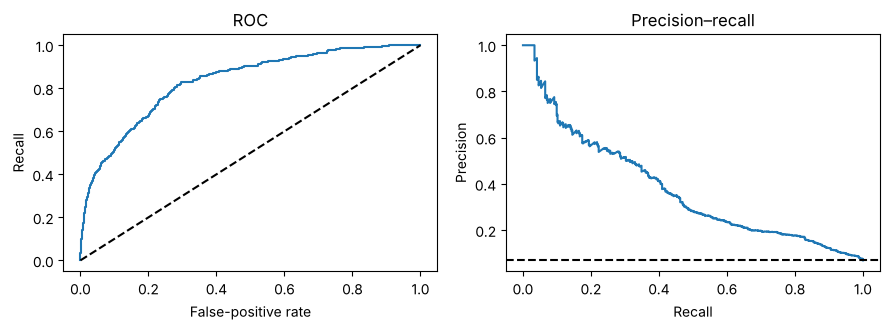

In [ ]:
def counts(y_true, actions):
    return confusion_matrix(y_true, actions, labels=[0,1]).ravel()
def report_metrics(y_true, p, t):
    action = p >= t
    precision, recall, _ = precision_recall_curve(y_true,p)
    return pd.Series(dict(precision=precision_score(y_true,action, zero_division=0),
        recall=recall_score(y_true,action), F1=f1_score(y_true,action),
        ROC_AUC=roc_auc_score(y_true,p), AP=average_precision_score(y_true,p),
        trapezoidal_PR_AUC=auc(recall,precision)))
m = report_metrics(y_test, y_prob, .5)
print('Rows actual good/default; columns approve/decline')
print(confusion_matrix(y_test,logistic_pred))
print(m.round(4))
fig, ax = plt.subplots(1,2,figsize=(9,3.4))
fp,tp,_ = roc_curve(y_test,y_prob)
pr,re,_ = precision_recall_curve(y_test,y_prob)
ax[0].plot(fp,tp); ax[0].plot([0,1],[0,1],'k--')
ax[0].set(xlabel='False-positive rate',ylabel='Recall',title='ROC')
ax[1].plot(re,pr); ax[1].axhline(y_test.mean(),ls='--',color='black')
ax[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall')
fig.tight_layout()
plt.show()

At 0.50, precision is 65.3% and recall is 11.9%: the model is nearly silent and catches only 49 of 413 defaults. F1 is 0.20.

**Why ROC AUC flatters.** ROC AUC of 0.832 is the probability that a randomly chosen default scores above a randomly chosen good loan. Prevalence does not enter that probability, but it changes what a point on the ROC curve means. The ROC x-axis is the false-positive rate, a share of the 5,587 good loans, so it compresses large absolute numbers of false alarms into small-looking distances. At the cost-chosen cutoff in Section 3.2, the false-positive rate is only 8.5%, a point near the left edge of the ROC plot that looks excellent. Yet that 8.5% is 474 good applicants declined against 199 defaults caught: 2.4 false alarms for every catch, and precision of 29.6%.

**Why the PR curve is more honest.** The precision-recall curve puts exactly that trade-off on its axes: of the applicants we decline, what share would actually have defaulted, and what share of all defaults we catch. Its reference line is prevalence (6.9%), not 0.5, and its denominator is the declines the lender actually makes, so the 93% of good loans cannot dilute it. Average precision of 0.376 is about 5.5 times the random-ranking baseline: real but modest screening power, which the 0.832 ROC AUC makes look stronger than it is.

### What does each mistake cost?
For a missed default I charge 60% of that applicant’s principal. For a mistaken decline I charge 8% foregone margin plus 1% for reputation and lost future business, 9% in total. Correct decisions incur zero error cost.

**Why 1%.** A good applicant who is wrongly declined is less likely to come back for the next loan or to take other products, and may tell others. Suppose a good customer’s future business is worth about one more loan of the same size at the same 8% margin, and about one in eight wrongly declined customers is lost for good. Then the expected cost is 8% × 1/8 = 1% of principal. I scale it with principal because larger relationships carry more future business. Because the figure is an assumption, I test it two ways below: a flat cost of about $225 per wrong decline (1% of the average loan), and mistaken-decline costs from 6% to 24% of principal.

For calibrated risk $p$ and principal $L$, approving costs $0.60Lp$ in expectation and declining costs $0.09L(1-p)$. Their crossover is $0.09/(0.60+0.09) \approx 0.13$.

The empirical curves below estimate expected cost per application by averaging realised costs. The sweep includes both endpoints and every distinct classification obtainable as the threshold varies. At ties I choose the highest threshold. The validation minimum sets the proposed operating point. The test minimum is a retrospective benchmark.

                            threshold    TN   FP   FN   TP    FPR  precision  recall        total $  $/application
approve all                    1.0000  5587    0  413    0 0.0000     0.0000  0.0000 6,306,540.0000     1,051.0900
default 0.5                    0.5000  5561   26  364   49 0.0047     0.6533  0.1186 5,558,670.0000       926.4450
cost crossover                 0.1304  4965  622  192  221 0.1113     0.2622  0.5351 4,255,146.0000       709.1910
validation minimum             0.1586  5113  474  214  199 0.0848     0.2957  0.4818 4,278,765.0000       713.1275
test minimum (descriptive)     0.1899  5242  345  227  186 0.0618     0.3503  0.4504 4,159,677.0000       693.2795

Validation rows 3,000 (206 defaults) | validation cost at its own minimum $567.08 vs $713.13 on test at the same cutoff

  LGD  FP rate  FP/FN  theory t  validation t  test $/app
 0.4     0.06 0.1500    0.1304        0.1586    475.4183
 0.4     0.09 0.2250    0.1837        0.1684    524.9468
 0.4     0.12 0.

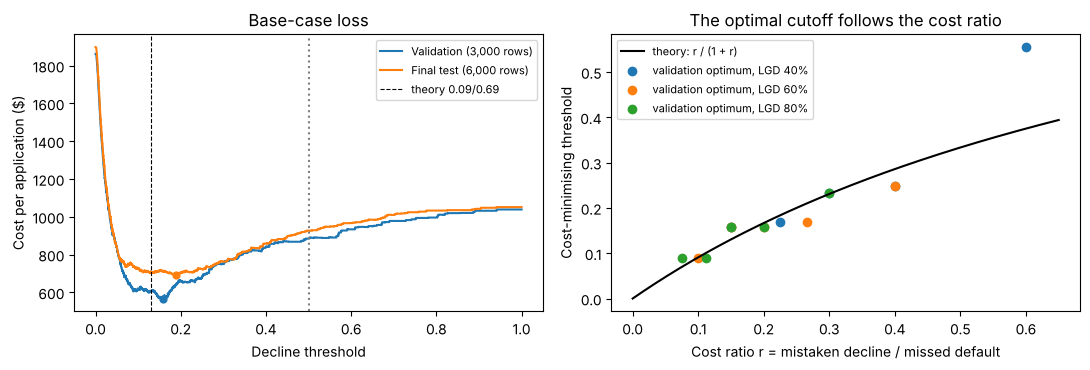

In [ ]:
def cost_curve(y_true, prob, amount, fn=.60, fp=.09, fixed=0.):
    y_true, amount = np.asarray(y_true), np.asarray(amount, dtype=float)
    order = np.argsort(prob)
    p = np.asarray(prob)[order]
    fp_cost = fp*amount + fixed            # mistaken-decline cost: margin share plus optional flat cost
    # Crossing a score switches that application from decline to approve.
    shift = np.where(y_true == 1, fn*amount, -fp_cost)
    initial = fp_cost[y_true == 0].sum()
    t = np.unique(np.r_[0., np.nextafter(p, 1.), 1.])
    crossed = np.searchsorted(p,t,side='left')
    costs = (initial + np.r_[0.,np.cumsum(shift[order])][crossed])/len(p)
    return pd.Series(costs,index=t)
def optimum(curve):
    return curve[curve == curve.min()].index.max()
def policyrow(t, prob=y_prob, fn=.60, fp=.09, fixed=0.):
    yt, L = np.asarray(y_test), X_test.loan_amount.to_numpy()
    decline = np.asarray(prob) >= t
    loss = np.where((yt == 1) & ~decline, fn*L, np.where((yt == 0) & decline, fp*L + fixed, 0))
    tn, fp_n, fn_n, tp = counts(yt, decline)
    return [t, tn, fp_n, fn_n, tp, fp_n/(fp_n+tn), tp/max(tp+fp_n, 1), tp/(tp+fn_n), loss.sum(), loss.mean()]
cols = ['threshold','TN','FP','FN','TP','FPR','precision','recall','total $','$/application']
p_val = model.predict_proba(X_val)[:,1]
curve = cost_curve(y_val,p_val,X_val.loan_amount)
test_curve = cost_curve(y_test,y_prob,X_test.loan_amount)
tv, tt = optimum(curve), optimum(test_curve)
bayes = .09/(.60+.09)
pol = pd.DataFrame([policyrow(t) for t in [1.,.5,bayes,tv,tt]],
    index=['approve all','default 0.5','cost crossover','validation minimum','test minimum (descriptive)'],
    columns=cols)
print(pol.to_string(float_format=lambda x: f'{x:,.4f}'))
print(f'\nValidation rows {len(y_val):,} ({int(sum(y_val))} defaults) | validation cost at its own minimum ${curve.min():,.2f} '
      f'vs ${pol.loc["validation minimum","$/application"]:,.2f} on test at the same cutoff')

# Sensitivity: vary both the mistaken-decline cost and the loss given default.
scenarios = []
for lgd in [.40, .60, .80]:
    for rate in [.06, .09, .12, .16, .24]:
        threshold = optimum(cost_curve(y_val, p_val, X_val.loan_amount, fn=lgd, fp=rate))
        scenarios.append([lgd, rate, rate/lgd, rate/(rate+lgd), threshold,
                          policyrow(threshold, fn=lgd, fp=rate)[-1]])
scen = pd.DataFrame(scenarios, columns=['LGD','FP rate','FP/FN','theory t','validation t','test $/app'])
print('\n', scen.round(4).to_string(index=False))

# Robustness: reputational cost as a flat amount per wrong decline instead of 1% of principal.
flat = .01 * X_fit.loan_amount.mean()
t_flat = optimum(cost_curve(y_val, p_val, X_val.loan_amount, fp=.08, fixed=flat))
print(f'\nFlat reputational cost ${flat:,.0f} per wrong decline: validation cutoff {t_flat:.4f} vs {tv:.4f}; '
      f'test $/app {policyrow(t_flat, fp=.08, fixed=flat)[-1]:,.2f} vs {policyrow(tv, fp=.08, fixed=flat)[-1]:,.2f} at the base cutoff')

fig, ax = plt.subplots(1,2,figsize=(11,3.8))
for label, series in [('Validation (3,000 rows)',curve),('Final test (6,000 rows)',test_curve)]:
    ax[0].step(series.index,series,where='post',label=label)
    ax[0].scatter(optimum(series),series.min(),s=24)
ax[0].axvline(.5,ls=':',color='gray'); ax[0].axvline(bayes,ls='--',color='black',lw=.8,label='theory 0.09/0.69')
ax[0].set(xlabel='Decline threshold',ylabel='Cost per application ($)',title='Base-case loss')
ax[0].legend(fontsize=8)
r = np.linspace(0, .65, 200)
ax[1].plot(r, r/(1+r), color='black', label='theory: r / (1 + r)')
for lgd, g in scen.groupby('LGD'):
    ax[1].scatter(g['FP/FN'], g['validation t'], label=f'validation optimum, LGD {lgd:.0%}')
ax[1].set(xlabel='Cost ratio r = mistaken decline / missed default', ylabel='Cost-minimising threshold',
          title='The optimal cutoff follows the cost ratio')
ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Distance from 0.5.** The cost-minimising threshold chosen on validation is 0.1586, 0.34 below the default of 0.50. The minimum on the test set itself is 0.1899, 0.31 below; I report it only as a benchmark, because choosing it would use the test outcomes.

**What it does to the confusion matrix** (test set, moving from 0.50 to 0.1586): missed defaults fall from 364 to 214, caught defaults rise from 49 to 199, and good applicants declined rise from 26 to 474. Cost per application falls from $926 to $713, against $1,051 for approving everyone.

**Two cautions from the curves.** First, the validation curve dips to $567 at its minimum, but the same cutoff costs $713 on test. The validation set has only 3,000 rows and 206 defaults, so its sharpest dip is partly noise and flatters the chosen cutoff. Second, the theory cutoff of 0.13, which needs no tuning at all, cost $709 on test, slightly less than the tuned cutoff. Between about 0.13 and 0.19 the test curve is nearly flat, so the exact cutoff matters far less than moving away from 0.5.

**How the optimum moves.** The table varies both costs. The validation optimum follows the theory line $r/(1+r)$, where $r$ is the cost of a mistaken decline divided by the cost of a missed default: it rises as declines get more expensive and falls as loss given default rises. The empirical points move in uneven steps (several scenarios share 0.1586) because the validation curve is flat near its minimum. The one large miss, 0.55 against a theory value of 0.375 when declines are very expensive and losses low, comes from a cost curve that is almost flat over a wide range. Switching the reputational cost to a flat $225 per wrong decline leaves the validation cutoff unchanged at 0.1586.

**Rule for the head of risk:** decline an application when its calibrated default probability exceeds

> cost of wrongly declining a good loan ÷ (cost of wrongly declining a good loan + cost of approving a loan that defaults).

At our costs (9% and 60% of principal) that is 9 ÷ 69 ≈ 13%. If loss given default rises to 80%, the cutoff falls to about 10%; if it falls to 40%, the cutoff rises to about 18%. If a wrong decline costs 16% instead of 9%, the cutoff rises to about 21%. A cutoff of 0.5 is correct only when the two mistakes cost the same, which in lending they almost never do.

## 4 · Testing the two claims
### A. Did the forest beat penalised logistic regression?
The model did not make the expected mistake: it chose McNemar’s test on the paired correctness of each test row rather than an independent-samples test on the two accuracies. What I changed was the direction. Its test was one-sided in the forest’s favour, so it can only ever conclude “forest better” and is blind to the opposite result. Here logistic was ahead (30 rows to 25), so the one-sided p of 0.79 says nothing about whether logistic is better. A one-sided test is also only legitimate if the direction was fixed before seeing any results. The question a model risk reviewer faces is whether the two models differ at all, so I use a two-sided test.

Choice of test: the exact binomial when there are fewer than 25 discordant rows, and the continuity-corrected chi-square at 25 or more. That is the standard rule of thumb at which the chi-square approximation to the binomial becomes reliable (an expected count of at least 12.5 in each discordant cell).

In [ ]:
rf_ok, lr_ok = forest_pred == y_test, logistic_pred == y_test
b = int(sum(rf_ok & ~lr_ok))
c = int(sum(~rf_ok & lr_ok))
n_disc = b+c
agreement = pd.DataFrame([[sum(rf_ok & lr_ok), b], [c, sum(~rf_ok & ~lr_ok)]],
    index=['forest correct','forest wrong'], columns=['logistic correct','logistic wrong'])
directional = binomtest(b,n_disc,.5,alternative='greater').pvalue if n_disc else 1.
if n_disc < 25:
    method = 'exact two-sided binomial'
    p_mc = binomtest(b,n_disc,.5).pvalue if n_disc else 1.
else:
    method = 'continuity-corrected chi-square'
    stat = max(0,abs(b-c)-1)**2/n_disc
    p_mc = chi2.sf(stat,1)
print(agreement)
print(f'b={b}, c={c}, b+c={n_disc}; one-sided exact p={directional:.6g}; {method}, two-sided p={p_mc:.6g}')

                logistic correct  logistic wrong
forest correct              5580              25
forest wrong                  30             365
b=25, c=30, b+c=55; one-sided exact p=0.790623; continuity-corrected chi-square, two-sided p=0.589639


Only the 55 rows where the models disagree carry evidence about which is better. The 5,580 rows both got right and the 365 both got wrong say nothing. The forest alone was correct 25 times and logistic alone 30 times. With 55 discordant rows, the prespecified procedure uses the continuity-corrected chi-square test: p = 0.59.

**Verdict:** my Step 2.2 conclusion survives. The forest is not shown to be better than penalised logistic regression, and the point estimate actually favours the logistic model, which is cheaper and easier to explain to a regulator.

**Limitation.** McNemar on accuracy tests whether the two models make different numbers of errors, and it weighs a wrongly declined good loan the same as a missed default. The comparison that matches the lending decision is a paired bootstrap: resample whole test rows and compare the two models’ dollar losses (or PR-AUC) on the same resampled rows, each at its own independently chosen threshold.

### B. Do the scores mean what they say?
I fit the Platt and isotonic maps on the separate calibration split, because the prompt’s “reuse y_test” would have fitted the calibrators on the test rows and then graded them on the same rows. The final test rows evaluate all three methods. Equal-frequency bins keep the sparse high-risk tail from dominating the diagram, and the vertical lines show 95% Wilson intervals. The identity for grouped forecasts is reliability − resolution + uncertainty; the printed residual accounts for within-bin variation in the original probabilities.

In [ ]:
p_cal = model.predict_proba(X_cal)[:,1]

Raw {'Brier': 0.052603541605008824, 'reliability': np.float64(8.285718472949128e-05), 'resolution': np.float64(0.008445583333333334), 'uncertainty': np.float64(0.06409530555555555), 'residual': np.float64(-0.0031290378019428813), 'reliability_change': np.float64(0.0)}
Platt {'Brier': 0.052585308890479555, 'reliability': np.float64(9.999073527433375e-05), 'resolution': np.float64(0.008445583333333334), 'uncertainty': np.float64(0.06409530555555555), 'residual': np.float64(-0.003164404067016992), 'reliability_change': np.float64(1.7133550544842476e-05)}
Isotonic {'Brier': 0.052676030203981684, 'reliability': np.float64(0.00010804519929346368), 'resolution': np.float64(0.007698180353034195), 'uncertainty': np.float64(0.06409530555555555), 'residual': np.float64(-0.0038291401978331335), 'reliability_change': np.float64(2.51880145639724e-05)}


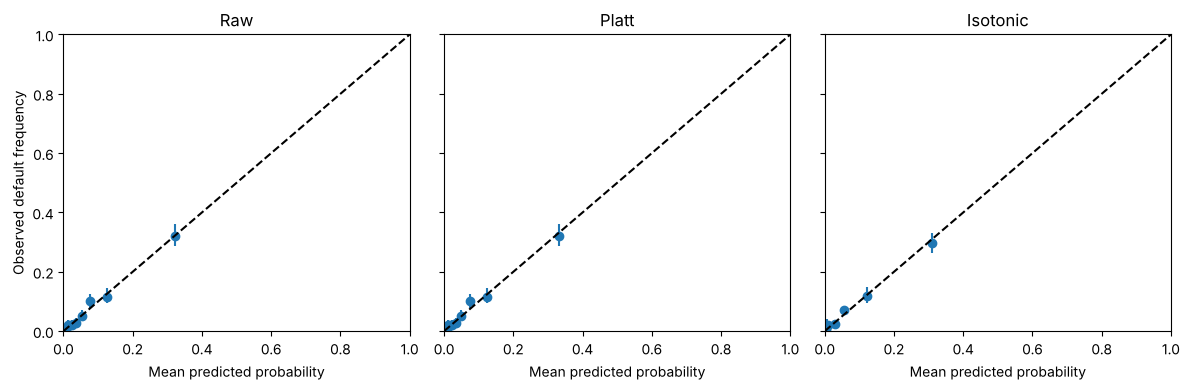

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

y_cal, p_cal, y_test, y_prob = map(
    np.asarray, (y_cal, p_cal, y_test, y_prob)
)

def logits(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return (np.log(p) - np.log1p(-p)).reshape(-1, 1)

platt = LogisticRegression(C=1e6).fit(logits(p_cal), y_cal)
iso = IsotonicRegression(out_of_bounds="clip").fit(p_cal, y_cal)
forecasts = {
    "Raw": y_prob,
    "Platt": platt.predict_proba(logits(y_prob))[:, 1],
    "Isotonic": iso.predict(y_prob),
}

def groups(p, minimum=50):
    cuts = np.unique(np.quantile(p, np.linspace(0, 1, 11)[1:-1]))
    labels = np.searchsorted(cuts, p, side="right")
    bins, pending = [], []
    for label in np.unique(labels):
        pending.extend(np.flatnonzero(labels == label))
        if len(pending) >= minimum:
            bins.append(pending)
            pending = []
    if pending:
        if bins:
            bins[-1].extend(pending)
        else:
            bins.append(pending)
    return bins

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
rate = y_test.mean()
unc = rate * (1 - rate)
for ax, (name, p) in zip(axes, forecasts.items()):
    bins = groups(p)
    n = np.array([len(i) for i in bins])
    x = np.array([p[i].mean() for i in bins])
    f = np.array([y_test[i].mean() for i in bins])
    rel = np.average((x - f)**2, weights=n)
    res = np.average((f - rate)**2, weights=n)
    bs = brier_score_loss(y_test, p)
    residual = bs - (rel - res + unc)
    if name == "Raw":
        baseline = rel
    print(name, dict(Brier=bs, reliability=rel, resolution=res,
                     uncertainty=unc, residual=residual,
                     reliability_change=rel - baseline))
    z = 1.96
    d = 1 + z*z/n
    center = (f + z*z/(2*n))/d
    half = z*np.sqrt(f*(1-f)/n + z*z/(4*n*n))/d
    ax.vlines(x, center-half, center+half)
    ax.scatter(x, f)
    ax.plot([0, 1], [0, 1], "k--")
    ax.set(title=name, xlabel="Mean predicted probability",
           xlim=(0, 1), ylim=(0, 1))
axes[0].set_ylabel("Observed default frequency")
fig.tight_layout()
plt.show()

In [ ]:
cal_results = []
for name, p in forecasts.items():
    local = (p >= tv-.025) & (p < tv+.025)
    k, m_ = int(y_test[local].sum()), int(local.sum())
    lo, hi = binomtest(k, m_).proportion_ci(method='wilson')
    cal_results.append([name,brier_score_loss(y_test,p), m_, p[local].mean(), y_test[local].mean(), lo, hi])
summary = pd.DataFrame(cal_results,columns=['map','Brier','near cutoff n','mean p','default rate','95% lo','95% hi']).set_index('map')
print(summary.round(5))
# Policy choice uses validation outcomes only. Test-set Brier differences are descriptive.
val_maps = {'Raw': p_val, 'Platt':platt.predict_proba(logits(p_val))[:,1], 'Isotonic':iso.predict(p_val)}
val_briers = {name:brier_score_loss(y_val,p) for name,p in val_maps.items()}
chosen = min(val_briers,key=val_briers.get)
final_t = optimum(cost_curve(y_val,val_maps[chosen],X_val.loan_amount))
final = policyrow(final_t,forecasts[chosen])
print('Validation-selected calibration map:', chosen)
print('Original and final thresholds:',tv, final_t)
print(pd.DataFrame([policyrow(tv), final], index=['raw scores, tuned cutoff', f'{chosen}, tuned cutoff'],
                   columns=cols).to_string(float_format=lambda x: f'{x:,.4f}'))

# A tuned cutoff depends only on ranking; the formula cutoff depends on calibration.
sq_val, sq_test = p_val**2, y_prob**2          # monotone distortion: same ranking, wrecked calibration
t_sq = optimum(cost_curve(y_val, sq_val, X_val.loan_amount))
changed = int(((sq_test >= t_sq) != (y_prob >= tv)).sum())
print(f'\nSquared scores: tuned cutoff {t_sq:.4f}, decisions changed {changed} of {len(y_prob):,}, '
      f'test $/app {policyrow(t_sq, sq_test)[-1]:,.2f}')
formula = pd.DataFrame([policyrow(bayes, p) for p in list(forecasts.values()) + [sq_test]],
                       index=[f'formula {bayes:.4f} on {k}' for k in forecasts] + [f'formula {bayes:.4f} on squared'],
                       columns=cols)
print(formula[['FP','FN','TP','$/application']].to_string(float_format=lambda x: f'{x:,.2f}'))

# Break-even assumptions for the recommended policy: when would approving everyone win?
yt, L = np.asarray(y_test), X_test.loan_amount.to_numpy()
dec = forecasts[chosen] >= final_t
caught, wrongly = L[(yt == 1) & dec].sum(), L[(yt == 0) & dec].sum()
print(f'\nSaving vs approve-all ${(.60*caught - .09*wrongly)/len(yt):,.2f} per application | '
      f'break-even LGD {.09*wrongly/caught:.1%} | break-even mistaken-decline cost {.60*caught/wrongly:.1%} of principal')

            Brier  near cutoff n   mean p  default rate   95% lo   95% hi
map                                                                      
Raw       0.05260            263  0.15614       0.10646  0.07469  0.14957
Platt     0.05259            248  0.15621       0.10887  0.07591  0.15377
Isotonic  0.05268            328  0.16459       0.11585  0.08558  0.15502
Validation-selected calibration map: Isotonic
Original and final thresholds: 0.15860505109066864 0.16190476190476194
                          threshold    TN   FP   FN   TP    FPR  precision  recall        total $  $/application
raw scores, tuned cutoff     0.1586  5113  474  214  199 0.0848     0.2957  0.4818 4,278,765.0000       713.1275
Isotonic, tuned cutoff       0.1619  5109  478  213  200 0.0856     0.2950  0.4843 4,275,258.0000       712.5430

Squared scores: tuned cutoff 0.0252, decisions changed 0 of 6,000, test $/app 713.13
                             FP   FN   TP  $/application
formula 0.1304 on Raw       622

**Verdict: the Phase 3 threshold survives the calibration check.** Recomputed on isotonic-calibrated probabilities, the cutoff moves from 0.1586 to 0.1619. On the test set it declines five more applicants (474 → 478 good loans declined, 199 → 200 defaults caught) and cost per application from $713.13 to $712.54. I report both and recommend the calibrated version as the standard procedure, not because it is measurably better.

**Why it survives.** My cutoff was chosen by minimising realised cost on validation outcomes, and that depends only on how the scores rank applicants. Any monotone distortion of the scores moves the numerical cutoff but declines the same people. The code shows this directly: squaring every score, which turns a 20% risk into 4% and wrecks calibration, gives a tuned cutoff of 0.025 that changes 0 of 6,000 decisions. Calibration matters for the *formula* cutoff of 13%, which takes the scores at face value. Applied to the squared scores, that formula catches only 97 defaults and costs $823 per application. On the real scores, the formula cutoff costs between $706 and $709 whichever calibration map is used, so it too survives.

**Global calibration.** The raw scores are already close to calibrated: the reliability term is under 0.0001, and the reliability diagram sits on the diagonal. Platt improved test Brier by 0.000018; isotonic, which won on validation, was slightly worse on test. The decomposition residual (about −0.003) is roughly 40 times the reliability term, so binning noise dominates and the reliability differences between the three maps are too small to mean anything. Calibration did not measurably improve these probabilities.

**Local calibration, where the decision is made.** The equal-frequency bins put the whole top decile, every score above about 0.15, into one point, which hides exactly the region where the cutoff sits. So I checked a window of ±0.025 around it. There, 263 loans averaged 15.6% predicted risk and defaulted at 10.6% (95% interval 7.5% to 15.0%). The raw scores overpredict by about five points near the cutoff, and the gap is just at the edge of significance. Neither Platt nor isotonic removes it. This would matter for the formula cutoff, since an applicant scored at 15% may truly be nearer 11%, below the 13% crossover. It does not affect the tuned cutoff, which was set on realised outcomes. It is the band to monitor during a pilot.

### Recommendation to the head of risk
**Do not sign on the strength of the 93% figure. Pilot the model with a 16% decline cutoff instead.**

The 93% accuracy proves nothing: approving every applicant is right 93.1% of the time and catches no defaults. Our model is only 0.4 points more accurate than that. Its value shows up in money, not accuracy. On 6,000 held-out simulated applications, approving everyone lost $1,051 per application; the model at the recommended cutoff lost $713, a saving of $339 per application. It caught 200 of 413 defaults and wrongly declined 478 of 5,587 good applicants. A random forest did no better (no significant difference), so there is no case for paying for the more complex model.

**Recommended cutoff:** decline applicants whose calibrated default probability exceeds 16%, not the usual 50%. At 50% the model catches only 49 defaults. The cutoff assumes a defaulted loan costs 60% of principal and a wrongly declined good applicant costs 9% (8% lost interest margin plus 1% lost future business). The general rule: decline when default probability exceeds the decline cost divided by the sum of both costs. Any cutoff between 13% and 19% performs about the same.

**What would change my answer:** loss given default. The model beats approving everyone as long as defaults cost more than about 21% of principal. If recoveries on this book are high enough to push losses below that, declining stops paying and I would not sign.

## AI Transcript
OpenAI Codex (GPT-6), November 24, 2026. Each exchange below records the prompt and the returned final reply before corrections. The Part B follow-up requests the omitted implementation.

### Part A

**Prompt**

[Prep] Act as a model risk analyst comparing two candidate credit models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The random forest got 0.9?? accuracy and the penalised logistic model got 0.9??. Write Python that tells me whether the forest is significantly better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

**Reply**

The rounded accuracies cannot determine a numerical p-value. Use a **one-sided exact McNemar test**. It counts the cases where exactly one model was correct and tests whether those cases favor the forest more often than expected under equal accuracy. genui{"citation":{"refs":["turn100744010search3","turn100744010search12"]}}

The code assumes `forest_pred` and `logistic_pred` contain class labels in the same case order as `y_test`. The two predictions for one borrower can be dependent, but borrowers must be independent. The one-sided interpretation assumes forest superiority was the hypothesis chosen before inspecting test results. genui{"citation":{"refs":["turn100744010search0","turn100744010search3"]}}

```python
import numpy as np  # Compare class labels case by case.
import pandas as pd  # Detect missing labels before counting correct predictions.
from scipy.stats import binomtest  # Compute the exact one-sided p-value.

y, rf, lr = map(np.asarray, (y_test, forest_pred, logistic_pred))  # Use your three existing arrays.
if y.ndim != 1 or not y.size or rf.shape != y.shape or lr.shape != y.shape:  # Check dimensions before comparison.
    raise ValueError("Supply three nonempty 1-D arrays of the same length.")  # Prevent accidental broadcasting.
if any(pd.isna(a).any() for a in (y, rf, lr)):  # Check outcomes and both prediction arrays.
    raise ValueError("Resolve missing labels before comparing accuracy.")  # Keep missing data out of the counts.
rf_ok, lr_ok = rf == y, lr == y  # Score each model against the same observed outcome.
b = int(np.count_nonzero(rf_ok & ~lr_ok))  # Count cases only the forest classified correctly.
c = int(np.count_nonzero(lr_ok & ~rf_ok))  # Count cases only logistic regression classified correctly.
p = binomtest(b, b + c, 0.5, alternative="greater").pvalue if b + c else 1.0  # Ties throughout give p = 1.
gap = 100 * (b - c) / y.size  # Calculate forest minus logistic accuracy in percentage points.
verdict = "supports" if p <= 0.05 else "does not establish"  # Use a 5% significance threshold.
print(f"The test set {verdict} higher accuracy for the forest than for penalised logistic regression (difference {gap:+.2f} percentage points, one-sided p = {p:.4g}).")  # Print the risk summary.
```

### Part B

**Prompt**

[Prep] Act as a model risk analyst at a bank, reviewing a credit scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities on a test set with about 7% prevalence. Write Python that assesses CALIBRATION -- a reliability diagram binning predicted probability against observed frequency, plus the Brier score and its decomposition -- and then applies both Platt scaling and isotonic regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and y_prob. Handle the sparse high-probability bins that low prevalence creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly -- high AUC -- and still be badly calibrated, and why that distinction decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold valid? If not, what should I do before using it?

**Reply**

The grouped Brier decomposition needs an explicit correction when a bin contains distinct forecast probabilities. Report the raw Brier score, reliability, resolution, uncertainty, and `raw_brier - (reliability - resolution + uncertainty)`. A lower raw Brier score establishes better overall probability forecasts on the evaluation sample. A smaller reliability term and a reliability curve closer to the diagonal support improved calibration.

Phase 3 threshold validity is **unverified**. A strictly increasing distortion such as \(p\mapsto p^2\) preserves every ranking and therefore AUC, but moves a 20% risk to a score of 4%. Fit the calibrators separately from evaluation, quantify uncertainty near the decision threshold, and compare realized decision costs on an untouched, deployment-representative cohort before relying on the cutoff.

### Part B follow-up

**Prompt**

Please supply the Python omitted from your initial reply. Use an independent calibration set y_cal and p_cal to fit the maps. Evaluate raw, Platt and isotonic probabilities on y_test and y_prob using quantile bins, reliability plots and the Brier decomposition. Keep the reply under 450 words.

**Reply**

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

y_cal, p_cal, y_test, y_prob = map(
    np.asarray, (y_cal, p_cal, y_test, y_prob)
)

def logits(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return (np.log(p) - np.log1p(-p)).reshape(-1, 1)

platt = LogisticRegression(C=1e6).fit(logits(p_cal), y_cal)
iso = IsotonicRegression(out_of_bounds="clip").fit(p_cal, y_cal)
forecasts = {
    "Raw": y_prob,
    "Platt": platt.predict_proba(logits(y_prob))[:, 1],
    "Isotonic": iso.predict(y_prob),
}

def groups(p, minimum=50):
    cuts = np.unique(np.quantile(p, np.linspace(0, 1, 11)[1:-1]))
    labels = np.searchsorted(cuts, p, side="right")
    bins, pending = [], []
    for label in np.unique(labels):
        pending.extend(np.flatnonzero(labels == label))
        if len(pending) >= minimum:
            bins.append(pending)
            pending = []
    if pending:
        if bins:
            bins[-1].extend(pending)
        else:
            bins.append(pending)
    return bins

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
rate = y_test.mean()
unc = rate * (1 - rate)
for ax, (name, p) in zip(axes, forecasts.items()):
    bins = groups(p)
    n = np.array([len(i) for i in bins])
    x = np.array([p[i].mean() for i in bins])
    f = np.array([y_test[i].mean() for i in bins])
    rel = np.average((x - f)**2, weights=n)
    res = np.average((f - rate)**2, weights=n)
    bs = brier_score_loss(y_test, p)
    residual = bs - (rel - res + unc)
    if name == "Raw":
        baseline = rel
    print(name, dict(Brier=bs, reliability=rel, resolution=res,
                     uncertainty=unc, residual=residual,
                     reliability_change=rel - baseline))
    z = 1.96
    d = 1 + z*z/n
    center = (f + z*z/(2*n))/d
    half = z*np.sqrt(f*(1-f)/n + z*z/(4*n*n))/d
    ax.vlines(x, center-half, center+half)
    ax.scatter(x, f)
    ax.plot([0, 1], [0, 1], "k--")
    ax.set(title=name, xlabel="Mean predicted probability",
           xlim=(0, 1), ylim=(0, 1))
axes[0].set_ylabel("Observed default frequency")
fig.tight_layout()
plt.show()
```

Negative `reliability_change` indicates lower estimated calibration error under the displayed binning. Each method uses its own quantile bins, so inspect the curves and 95% Wilson intervals alongside that comparison. The residual reconciles the grouped decomposition with the individual-prediction Brier score.

### Verification and changes

- **Part A.** The model chose a paired test (McNemar), so the expected independent-samples error did not occur. I changed its one-sided test to two-sided, because the direction was not fixed in advance and logistic, not the forest, was ahead. I also added the agreement table and the exact-binomial/chi-square rule.
- **Part B.** The first reply explained the residual and the ranking argument but omitted executable Python. I asked for the code and supplied a separate calibration set, because the prompt’s “reuse y_test” would have fitted the calibrators on the same rows used to grade them.
- **Part B follow-up.** I ran the supplied code unchanged. I then added the window check around the cutoff (the top bin hides it), validation-only selection of the calibration map, the recomputed threshold, and the squared-score demonstration that a tuned cutoff depends on ranking while the formula cutoff depends on calibration.